In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.data.load_data import (
    load_course_genre,
    load_courses,
    load_ratings,
    load_user_profiles,
)
from src.data.preprocess import (
    get_dataset_summary,
    validate_no_duplicates,
    validate_no_missing_values,
)

DATA_DIR = PROJECT_ROOT / "data" / "raw"

print(f"Project root: {PROJECT_ROOT}")
print(f"Data directory: {DATA_DIR}")

Project root: /home/Tam-Davies/Projects/ml-course-recommender
Data directory: /home/Tam-Davies/Projects/ml-course-recommender/data/raw


In [2]:
course_genre = load_course_genre(DATA_DIR)
courses = load_courses(DATA_DIR)
ratings = load_ratings(DATA_DIR)
user_profiles = load_user_profiles(DATA_DIR)

datasets = {
    "course_genre": course_genre,
    "courses": courses,
    "ratings": ratings,
    "user_profiles": user_profiles,
}

print("Datasets loaded successfully.")

Datasets loaded successfully.


In [3]:
summary = get_dataset_summary(datasets)

summary

,rows,columns
course_genre,307,16
courses,307,3
ratings,233306,3
user_profiles,33901,15


In [4]:
missing_check = validate_no_missing_values(datasets)
duplicate_check = validate_no_duplicates(datasets)

validation = pd.DataFrame({
    "No Missing Values": missing_check,
    "No Duplicate Rows": duplicate_check,
})

validation

,No Missing Values,No Duplicate Rows
course_genre,True,True
courses,True,True
ratings,True,True
user_profiles,True,True


In [5]:
genre_columns = [
    column
    for column in course_genre.columns
    if column not in ["COURSE_ID", "TITLE"]
]

genre_counts = course_genre[genre_columns].sum().sort_values(ascending=False)

genre_counts

BackendDev         78
MachineLearning    69
Database           60
DataAnalysis       56
DataScience        38
CloudComputing     37
BigData            36
Python             28
FrontendDev        19
Containers         17
R                  17
ComputerVision     10
Chatbot             4
Blockchain          4
dtype: int64

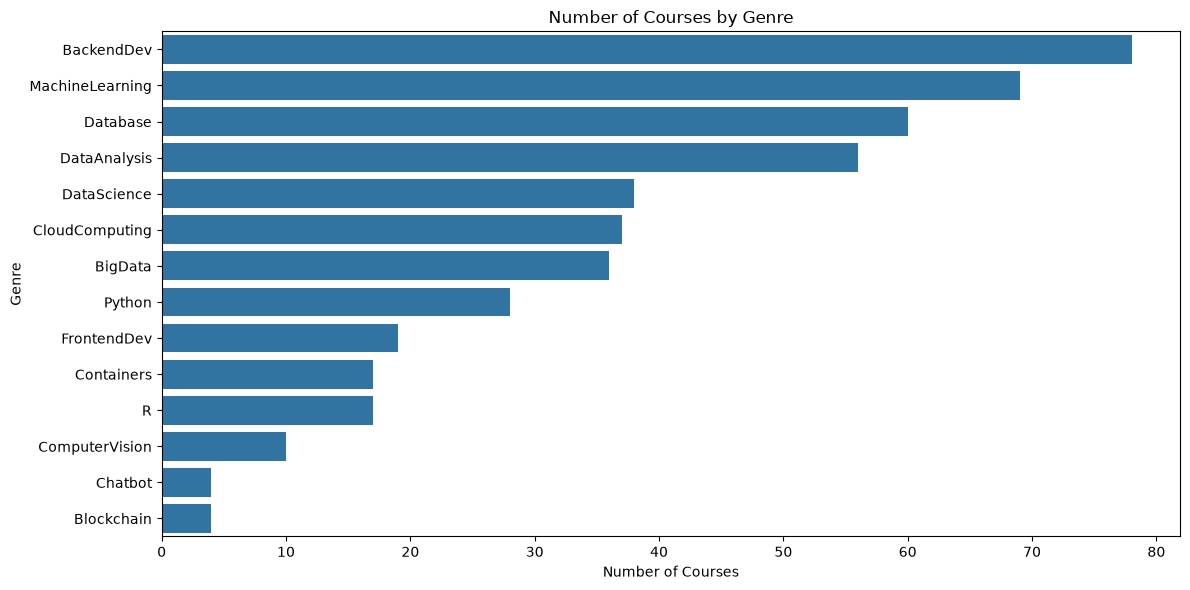

In [6]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index,
)

plt.title("Number of Courses by Genre")
plt.xlabel("Number of Courses")
plt.ylabel("Genre")
plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports" / "figures" / "courses_by_genre.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [7]:
rating_summary = ratings["rating"].describe()

rating_summary

count    233306.000000
mean          2.952954
std           0.211737
min           2.000000
25%           3.000000
50%           3.000000
75%           3.000000
max           3.000000
Name: rating, dtype: float64

In [8]:
rating_counts = (
    ratings["rating"]
    .value_counts()
    .sort_index()
)

rating_counts

rating
2.0     10976
3.0    222330
Name: count, dtype: int64

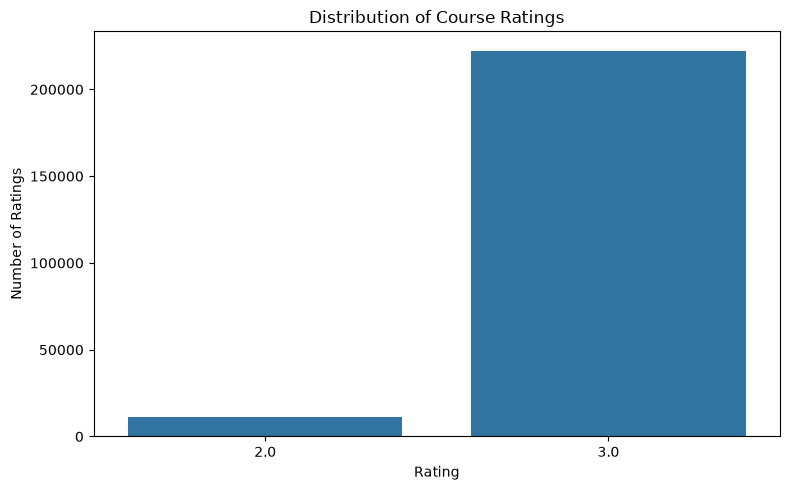

In [9]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,
)

plt.title("Distribution of Course Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports" / "figures" / "rating_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [10]:
# User and course interaction statistics

user_activity = ratings.groupby("user").size()
course_activity = ratings.groupby("item").size()

eda_summary = pd.DataFrame({
    "Metric": [
        "Unique users with ratings",
        "Unique courses with ratings",
        "Total ratings",
        "Average ratings per user",
        "Median ratings per user",
        "Average ratings per course",
        "Median ratings per course",
    ],
    "Value": [
        ratings["user"].nunique(),
        ratings["item"].nunique(),
        len(ratings),
        user_activity.mean(),
        user_activity.median(),
        course_activity.mean(),
        course_activity.median(),
    ],
})

eda_summary

,Metric,Value
0,Unique users with ratings,33901.000000
1,Unique courses with ratings,126.000000
2,Total ratings,233306.000000
3,Average ratings per user,6.881980
4,Median ratings per user,6.000000
5,Average ratings per course,1851.634921
6,Median ratings per course,634.000000


In [11]:
top_courses = (
    ratings.groupby("item")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .rename("rating_count")
    .reset_index()
)

top_courses = top_courses.merge(
    course_genre[["COURSE_ID", "TITLE"]],
    left_on="item",
    right_on="COURSE_ID",
    how="left",
)

top_courses[["COURSE_ID", "TITLE", "rating_count"]]

,COURSE_ID,TITLE,rating_count
0,PY0101EN,python for data science,14936
1,DS0101EN,introduction to data science,14477
2,BD0101EN,big data 101,13291
3,BD0111EN,hadoop 101,10599
4,DA0101EN,data analysis with python,8303
5,DS0103EN,data science methodology,7719
6,ML0101ENv3,machine learning with python,7644
7,BD0211EN,spark fundamentals i,7551
8,DS0105EN,data science hands on with open source tools,7199
9,BC0101EN,blockchain essentials,6719


In [12]:
profile_features = user_profiles.drop(columns="user")

profile_summary = pd.DataFrame({
    "mean": profile_features.mean(),
    "median": profile_features.median(),
    "max": profile_features.max(),
}).sort_values("mean", ascending=False)

profile_summary

,mean,median,max
Database,5.518569,3.0,63.0
DataScience,5.087343,3.0,32.0
BigData,4.750450,2.0,54.0
DataAnalysis,3.624701,3.0,48.0
Python,3.493791,3.0,18.0
MachineLearning,3.048022,0.0,39.0
CloudComputing,2.307100,0.0,38.0
BackendDev,2.269461,0.0,54.0
R,1.017433,0.0,18.0
Containers,0.998938,0.0,15.0


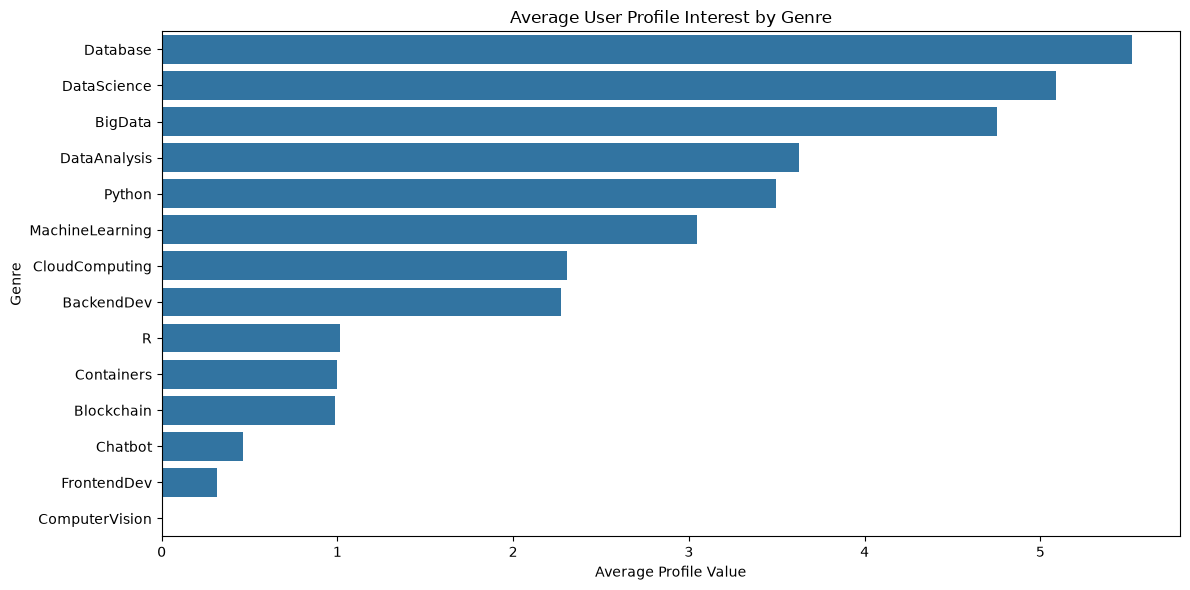

In [13]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=profile_summary["mean"].values,
    y=profile_summary.index,
)

plt.title("Average User Profile Interest by Genre")
plt.xlabel("Average Profile Value")
plt.ylabel("Genre")
plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "reports" / "figures" / "average_user_profile_interest.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()